# Bonus — Outlier detection and future orders forecasting

Compare two causal outlier treatments, seasonal naive and a PyTorch GRU. Forecast regional order totals for the next 15 and 60 minutes using three rolling-origin folds. All choices below are experiment settings.

In [2]:
import random
import sqlite3
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
OUT = PROJECT / 'notebooks' / 'task3_results'
OUT.mkdir(parents=True, exist_ok=True)
ARCHIVE = PROJECT / 'F26.ML.Assignment.One.data.db.zip'
DB = PROJECT / 'notebooks' / 'data' / 'F26.ML.Assignment.One.data.db'
STEP = 5
HORIZONS = [15, 60]
STEPS = np.array(HORIZONS) // STEP
DAY = 24 * 60 // STEP
LOOKBACK = DAY
STRIDE = 60 // STEP
EPOCHS = 5
BATCH_SIZE = 128
print('Device:', DEVICE)

Device: cuda


## Data reading and exploration

Place the supplied database ZIP in the project root. Join the unique region property to each order before aggregation.

Missing regions: 0


,orders,stores,start,end
region,,,,
683,243467,458,2024-05-08 00:01:12,2024-09-05 15:25:25
685,37766,123,2024-05-08 00:44:26,2024-09-05 15:16:47
687,9242,73,2024-05-08 00:39:21,2024-09-05 14:17:28
689,16131,74,2024-05-08 00:25:50,2024-09-05 15:02:46
691,10968,66,2024-05-08 00:01:38,2024-09-05 15:08:23
693,13638,60,2024-05-08 00:37:40,2024-09-05 15:10:18
695,46427,170,2024-05-08 00:06:20,2024-09-05 15:14:24
697,5131,47,2024-05-08 02:12:17,2024-09-05 13:57:53
703,23543,65,2024-05-08 00:01:46,2024-09-05 15:07:08


Duplicate order IDs: 0
Time range: 2024-05-09 00:00:00 2024-09-04 23:55:00 Regions: 13
Zero-bin fraction: {'683': 0.142, '685': 0.453, '687': 0.785, '689': 0.673, '691': 0.754, '693': 0.718, '695': 0.393, '697': 0.869, '703': 0.583, '705': 0.852, '707': 0.29, '709': 0.754, '717': 0.88}


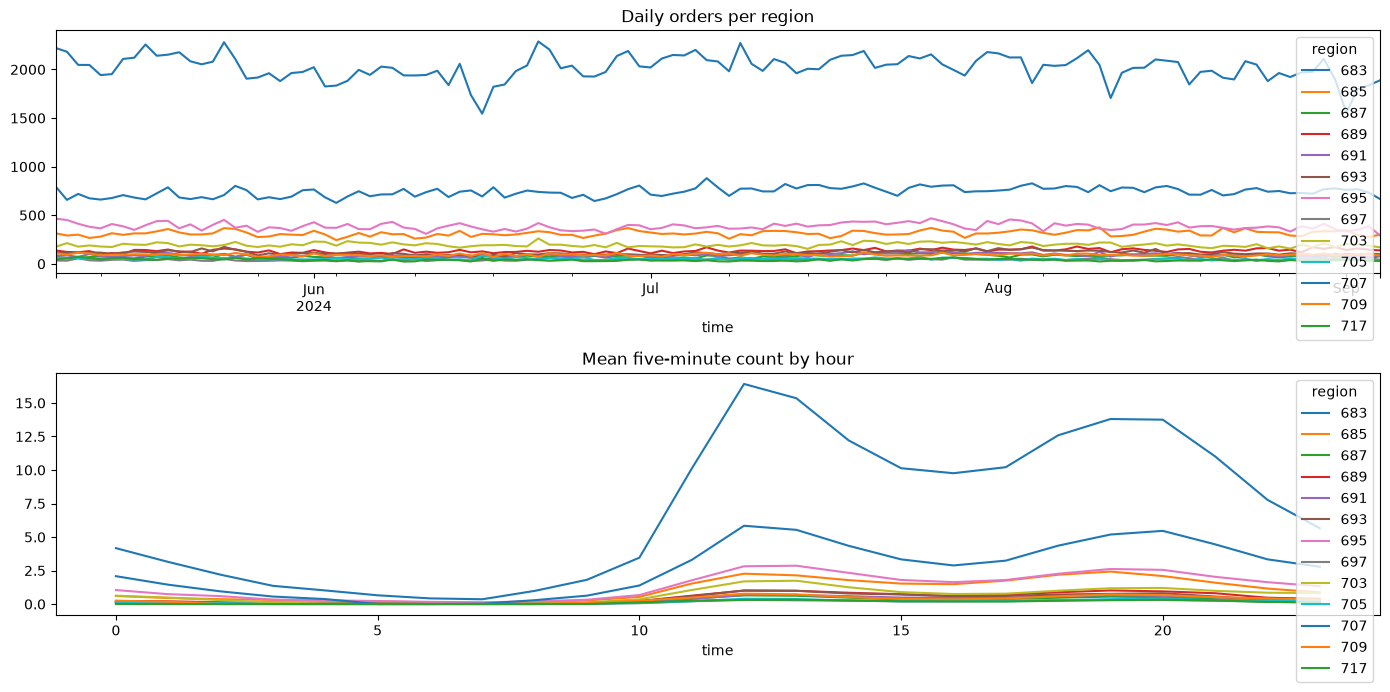

In [3]:
if not DB.exists():
    if not ARCHIVE.exists():
        raise FileNotFoundError(f'Copy the assignment database archive to {ARCHIVE}')
    DB.parent.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ARCHIVE) as archive:
        member = next(name for name in archive.namelist() if name.endswith('.db') and not name.startswith('__MACOSX/'))
        with archive.open(member) as source, DB.open('wb') as destination:
            import shutil
            shutil.copyfileobj(source, destination)
with sqlite3.connect(f'{DB.as_uri()}?mode=ro', uri=True) as connection:
    orders = pd.read_sql_query('SELECT order_id, store_id, DATE_CREATE FROM order_history', connection)
    regions = pd.read_sql_query('SELECT order_id, VALUE AS region FROM order_props_value WHERE ORDER_PROPS_ID = 11', connection)
assert orders.order_id.is_unique
assert regions.order_id.is_unique
orders = orders.merge(regions, on='order_id', how='left', validate='one_to_one')
print('Missing regions:', orders.region.isna().sum())
assert orders.region.notna().all()
orders['time'] = pd.to_datetime(orders.DATE_CREATE, format='mixed', errors='raise')
display(orders.groupby('region').agg(orders=('order_id','size'), stores=('store_id','nunique'), start=('time','min'), end=('time','max')))
print('Duplicate order IDs:', orders.order_id.duplicated().sum())
first_day = orders.time.min().normalize() + pd.Timedelta(days=1)
last_day = orders.time.max().normalize()
complete = orders[(orders.time >= first_day) & (orders.time < last_day)].copy()
complete['bin'] = complete.time.dt.floor('5min')
grid = pd.date_range(first_day, last_day, freq='5min', inclusive='left')
counts = complete.groupby(['bin','region']).size().unstack(fill_value=0).reindex(grid, fill_value=0).sort_index(axis=1).astype(float)
counts.index.name = 'time'
region_names = list(counts.columns)
print('Time range:', grid[0], grid[-1], 'Regions:', len(region_names))
print('Zero-bin fraction:', (counts == 0).mean().round(3).to_dict())
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
counts.resample('D').sum().plot(ax=axes[0], title='Daily orders per region')
counts.groupby(counts.index.hour).mean().plot(ax=axes[1], title='Mean five-minute count by hour')
plt.tight_layout()
plt.show()

The outer partial days are excluded. Empty bins are treated as zero observed orders, assuming the supplied extract covers the retained interval continuously. Region activity and daily plots should be checked for outages. Timestamps are used as recorded because the database supplies no timezone. Targets are counts of new order IDs, aggregated across stores in each region.

## Causal outlier detection

Compare a rolling median/MAD detector with a seasonal residual detector. Cap flagged counts to preserve the regular time grid. Large genuine demand peaks can also be flagged, so validation targets remain unchanged.

In [4]:
def clean_history(frame, method, train_end):
    if method == 'raw':
        return frame.copy(), pd.DataFrame(False, index=frame.index, columns=frame.columns)
    if method == 'rolling_mad':
        center = frame.shift(1).rolling(DAY, min_periods=24).median()
        deviations = (frame - center).abs()
        scale = deviations.shift(1).rolling(DAY, min_periods=24).median() * 1.4826
        radius = 3 * scale.clip(lower=1)
        lower, upper = (center - radius).clip(lower=0), center + radius
    else:
        center = frame.shift(DAY)
        residual = frame - center
        training_residual = residual.iloc[:train_end]
        offset = training_residual.median()
        scale = (training_residual - offset).abs().median() * 1.4826
        radius = 3 * scale.clip(lower=1)
        lower = (center + offset - radius).clip(lower=0)
        upper = center + offset + radius
    flags = frame.lt(lower) | frame.gt(upper)
    cleaned = frame.clip(lower=lower, upper=upper, axis=None)
    return cleaned.fillna(frame), flags

METHODS = ['raw', 'rolling_mad', 'seasonal_residual']
fold_size = 7 * DAY
folds = [(len(counts) - (3 - fold) * fold_size, len(counts) - (2 - fold) * fold_size) for fold in range(3)]
assert folds[0][0] > 2 * DAY
pd.DataFrame([{'fold': i+1, 'train_end': counts.index[start], 'validation_end': counts.index[end-1]} for i,(start,end) in enumerate(folds)])

,fold,train_end,validation_end
0,1,2024-08-15,2024-08-21 23:55:00
1,2,2024-08-22,2024-08-28 23:55:00
2,3,2024-08-29,2024-09-04 23:55:00


rolling_mad training outlier fraction: 0.006412981859410431
seasonal_residual training outlier fraction: 0.01501722483865341
Detector Jaccard overlap: 0.15293255131964809


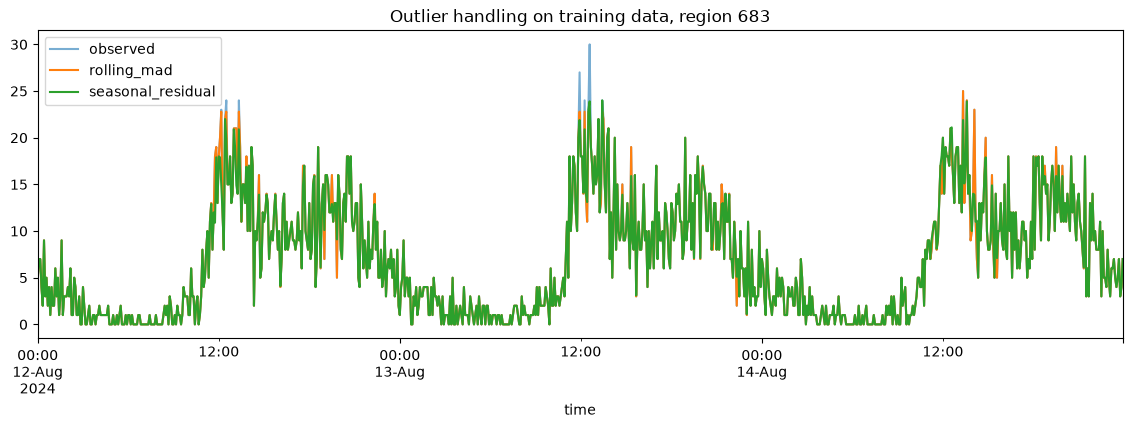

In [5]:
first_end = folds[0][0]
flag_tables = {}
cleaned_preview = {}
for method in METHODS[1:]:
    cleaned, flags = clean_history(counts, method, first_end)
    flag_tables[method] = flags.iloc[:first_end]
    cleaned_preview[method] = cleaned
    print(method, 'training outlier fraction:', flags.iloc[:first_end].to_numpy().mean())
intersection = (flag_tables['rolling_mad'] & flag_tables['seasonal_residual']).to_numpy().sum()
union = (flag_tables['rolling_mad'] | flag_tables['seasonal_residual']).to_numpy().sum()
print('Detector Jaccard overlap:', intersection / max(union, 1))
plot_region = counts.iloc[:first_end].sum().idxmax()
window = slice(first_end - DAY * 3, first_end)
fig, ax = plt.subplots(figsize=(14, 4))
counts[plot_region].iloc[window].plot(ax=ax, label='observed', alpha=0.6)
for method in METHODS[1:]:
    cleaned_preview[method][plot_region].iloc[window].plot(ax=ax, label=method)
ax.set_title('Outlier handling on training data, region ' + str(plot_region))
ax.legend()
plt.show()

## Forecasting models and rolling-origin validation

Use expanding training windows and three subsequent seven-day folds. Issue forecasts hourly. Each input contains one day of past counts and cyclical calendar features. The GRU predicts both future totals. Training targets end before the validation boundary. Five fixed epochs avoid selecting a model on the reporting fold.

In [6]:
class OrderWindows(Dataset):
    def __init__(self, inputs, targets, origins, scale, times):
        self.inputs = np.asarray(inputs, dtype=np.float32)
        self.targets = np.asarray(targets, dtype=np.float32)
        self.origins = origins
        self.scale = np.asarray(scale, dtype=np.float32)
        self.cumulative = np.vstack([np.zeros((1, self.targets.shape[1])), self.targets.cumsum(axis=0)])
        hour = (times.hour + times.minute / 60).to_numpy()
        weekday = times.dayofweek.to_numpy()
        self.calendar = np.column_stack([np.sin(2*np.pi*hour/24), np.cos(2*np.pi*hour/24), np.sin(2*np.pi*weekday/7), np.cos(2*np.pi*weekday/7)]).astype(np.float32)

    def __len__(self):
        return len(self.origins) * self.inputs.shape[1]

    def __getitem__(self, index):
        position, region = divmod(index, self.inputs.shape[1])
        origin = self.origins[position]
        values = self.inputs[origin-LOOKBACK:origin, region] / self.scale[region]
        x = np.column_stack([values, self.calendar[origin-LOOKBACK:origin]])
        totals = self.cumulative[origin+STEPS, region] - self.cumulative[origin, region]
        y = totals / (self.scale[region] * STEPS)
        return torch.tensor(x, dtype=torch.float32), torch.tensor(region), torch.tensor(y, dtype=torch.float32)

class OrderGRU(nn.Module):
    def __init__(self, regions):
        super().__init__()
        self.region_embedding = nn.Embedding(regions, 4)
        self.gru = nn.GRU(5, 32, batch_first=True)
        self.head = nn.Sequential(nn.Linear(36, 2), nn.Softplus())

    def forward(self, x, region):
        _, hidden = self.gru(x)
        return self.head(torch.cat([hidden[-1], self.region_embedding(region)], dim=1))

def predict_gru(model, loader, scale):
    predictions = []
    model.eval()
    with torch.no_grad():
        for x, region, target in loader:
            output = model(x.to(DEVICE), region.to(DEVICE)).cpu().numpy()
            predictions.append(output * scale[region.numpy(), None] * STEPS)
    return np.concatenate(predictions)

def seasonal_naive(values, origins):
    predictions = []
    for origin in origins:
        predictions.append(np.column_stack([values[origin-DAY:origin-DAY+step].sum(axis=0) for step in STEPS]))
    return np.concatenate(predictions)

def observed_totals(values, origins):
    return np.concatenate([np.column_stack([values[t:t+step].sum(axis=0) for step in STEPS]) for t in origins])

In [7]:
metric_rows, prediction_rows, outlier_rows = [], [], []
for fold, (start, end) in enumerate(folds, 1):
    train_origins = np.arange(LOOKBACK, start - max(STEPS) + 1, STRIDE)
    val_origins = np.arange(start, end - max(STEPS) + 1, STRIDE)
    region_ids = np.tile(np.arange(len(region_names)), len(val_origins))
    true = observed_totals(counts.to_numpy(), val_origins)
    for method in METHODS:
        cleaned, flags = clean_history(counts.iloc[:end], method, start)
        outlier_rows.append({'fold': fold, 'method': method, 'train_flag_fraction': flags.iloc[:start].to_numpy().mean(), 'validation_flag_fraction': flags.iloc[start:].to_numpy().mean()})
        scale = cleaned.iloc[:start].std().clip(lower=1).to_numpy(dtype=np.float32)
        training = OrderWindows(cleaned, cleaned, train_origins, scale, counts.index[:end])
        validation = OrderWindows(cleaned, counts.iloc[:end], val_origins, scale, counts.index[:end])
        generator = torch.Generator().manual_seed(SEED)
        train_loader = DataLoader(training, batch_size=BATCH_SIZE, shuffle=True, generator=generator)
        val_loader = DataLoader(validation, batch_size=BATCH_SIZE, shuffle=False)
        torch.manual_seed(SEED)
        model = OrderGRU(len(region_names)).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
        writer = SummaryWriter(str(OUT / 'runs' / f'fold{fold}_{method}'))
        for epoch in range(EPOCHS):
            model.train()
            total_loss = 0
            for x, region, y in train_loader:
                optimizer.zero_grad()
                prediction = model(x.to(DEVICE), region.to(DEVICE))
                loss = nn.functional.mse_loss(prediction, y.to(DEVICE))
                loss.backward()
                optimizer.step()
                total_loss += loss.item() * len(x)
            predicted = predict_gru(model, val_loader, scale)
            writer.add_scalar('train/scaled_mse', total_loss / len(training), epoch + 1)
            for j, horizon in enumerate(HORIZONS):
                writer.add_scalar(f'validation/MAE_{horizon}', mean_absolute_error(true[:,j], predicted[:,j]), epoch+1)
                writer.add_scalar(f'validation/RMSE_{horizon}', np.sqrt(mean_squared_error(true[:,j], predicted[:,j])), epoch+1)
            print('Fold', fold, method, 'epoch', epoch+1, 'loss', round(total_loss / len(training), 4))
        writer.close()
        torch.save({'state_dict': model.cpu().state_dict(), 'scale': torch.tensor(scale), 'regions': [str(r) for r in region_names], 'horizons': HORIZONS, 'lookback': LOOKBACK, 'step_minutes': STEP, 'method': method, 'train_end': str(counts.index[start])}, OUT / f'gru_fold{fold}_{method}.pt')
        predictions = {'GRU': predicted, 'seasonal_naive': seasonal_naive(cleaned.to_numpy(), val_origins)}
        for model_name, values in predictions.items():
            for j, horizon in enumerate(HORIZONS):
                for region_id, region_name in enumerate(region_names):
                    mask = region_ids == region_id
                    metric_rows.append({'fold': fold, 'method': method, 'model': model_name, 'horizon': horizon, 'region': region_name, 'MAE': mean_absolute_error(true[mask,j], values[mask,j]), 'RMSE': np.sqrt(mean_squared_error(true[mask,j], values[mask,j]))})
                prediction_rows.append(pd.DataFrame({'fold': fold, 'method': method, 'model': model_name, 'horizon': horizon, 'time': np.repeat(counts.index[val_origins], len(region_names)), 'region': np.tile(region_names, len(val_origins)), 'true': true[:,j], 'predicted': values[:,j]}))
        pd.DataFrame(metric_rows).to_csv(OUT / 'region_metrics.csv', index=False)
        pd.concat(prediction_rows, ignore_index=True).to_csv(OUT / 'predictions.csv', index=False)
        del model, optimizer
outlier_report = pd.DataFrame(outlier_rows)
outlier_report.to_csv(OUT / 'outlier_rates.csv', index=False)
display(outlier_report)

Fold 1 raw epoch 1 loss 0.1899
Fold 1 raw epoch 2 loss 0.1122
Fold 1 raw epoch 3 loss 0.1011
Fold 1 raw epoch 4 loss 0.096
Fold 1 raw epoch 5 loss 0.0927
Fold 1 rolling_mad epoch 1 loss 0.1846
Fold 1 rolling_mad epoch 2 loss 0.1063
Fold 1 rolling_mad epoch 3 loss 0.0955
Fold 1 rolling_mad epoch 4 loss 0.0905
Fold 1 rolling_mad epoch 5 loss 0.0874
Fold 1 seasonal_residual epoch 1 loss 0.1899
Fold 1 seasonal_residual epoch 2 loss 0.1089
Fold 1 seasonal_residual epoch 3 loss 0.0976
Fold 1 seasonal_residual epoch 4 loss 0.0924
Fold 1 seasonal_residual epoch 5 loss 0.0892
Fold 2 raw epoch 1 loss 0.1858
Fold 2 raw epoch 2 loss 0.1103
Fold 2 raw epoch 3 loss 0.1001
Fold 2 raw epoch 4 loss 0.0951
Fold 2 raw epoch 5 loss 0.0921
Fold 2 rolling_mad epoch 1 loss 0.1802
Fold 2 rolling_mad epoch 2 loss 0.1044
Fold 2 rolling_mad epoch 3 loss 0.0945
Fold 2 rolling_mad epoch 4 loss 0.0898
Fold 2 rolling_mad epoch 5 loss 0.0868
Fold 2 seasonal_residual epoch 1 loss 0.1853
Fold 2 seasonal_residual epoch 

,fold,method,train_flag_fraction,validation_flag_fraction
0,1,raw,0.000000,0.000000
1,1,rolling_mad,0.006413,0.005609
2,1,seasonal_residual,0.015017,0.013545
3,2,raw,0.000000,0.000000
4,2,rolling_mad,0.006359,0.005266
5,2,seasonal_residual,0.014919,0.014080
6,3,raw,0.000000,0.000000
7,3,rolling_mad,0.006291,0.005037
8,3,seasonal_residual,0.014867,0.013164


## Evaluation

Report pooled MAE/RMSE on original validation counts and regional metrics. Negative changes relative to raw data indicate improvement. All horizons and treatments use the same forecast origins.

MAE                RMSE  \
                                              mean       std      mean   
method            model          horizon                                 
raw               GRU            15       1.164979  0.044588  1.990217   
                                 60       2.814410  0.084027  5.115519   
                  seasonal_naive 15       1.490690  0.030415  2.748680   
                                 60       3.278388  0.088430  6.163039   
rolling_mad       GRU            15       1.163303  0.045895  1.991389   
                                 60       2.807347  0.089463  5.104404   
                  seasonal_naive 15       1.478816  0.027575  2.726607   
                                 60       3.241983  0.088176  6.087302   
seasonal_residual GRU            15       1.164360  0.039169  1.989193   
                                 60       2.812262  0.101932  5.115493   
                  seasonal_naive 15       1.472888  0.032253  2.696611   
                                 60       3.230834  0.085677  6.087669   

                                                    
                                               std  
method            model          horizon            
raw               GRU            15       0.127684  
                                 60       0.136184  
                  seasonal_naive 15       0.092123  
                                 60       0.235877  
rolling_mad       GRU            15       0.128462  
                                 60       0.114281  
                  seasonal_naive 15       0.093760  
                                 60       0.246287  
seasonal_residual GRU            15       0.119289  
                                 60       0.182403  
                  seasonal_naive 15       0.083712  
                                 60       0.244749

MAE      RMSE
method            model          horizon region                    
raw               GRU            15      683     3.560268  4.902304
                                         685     1.446180  1.944522
                                         687     0.677587  0.968039
                                         689     0.913894  1.282940
                                         691     0.743530  0.994205
...                                                   ...       ...
seasonal_residual seasonal_naive 60      703     2.751984  4.039372
                                         705     1.295635  2.044357
                                         707     5.944537  8.410802
                                         709     1.807540  2.701040
                                         717     0.974206  1.658829

[156 rows x 2 columns]

,method,model,horizon,MAE,RMSE,MAE_raw,RMSE_raw,MAE_change,RMSE_change
0,raw,GRU,15,1.164979,1.990217,1.164979,1.990217,0.000000,0.000000
1,raw,GRU,60,2.814410,5.115519,2.814410,5.115519,0.000000,0.000000
2,raw,seasonal_naive,15,1.490690,2.748680,1.490690,2.748680,0.000000,0.000000
3,raw,seasonal_naive,60,3.278388,6.163039,3.278388,6.163039,0.000000,0.000000
4,rolling_mad,GRU,15,1.163303,1.991389,1.164979,1.990217,-0.001676,0.001172
5,rolling_mad,GRU,60,2.807347,5.104404,2.814410,5.115519,-0.007062,-0.011115
6,rolling_mad,seasonal_naive,15,1.478816,2.726607,1.490690,2.748680,-0.011874,-0.022073
7,rolling_mad,seasonal_naive,60,3.241983,6.087302,3.278388,6.163039,-0.036405,-0.075738
8,seasonal_residual,GRU,15,1.164360,1.989193,1.164979,1.990217,-0.000619,-0.001024
9,seasonal_residual,GRU,60,2.812262,5.115493,2.814410,5.115519,-0.002148,-0.000026


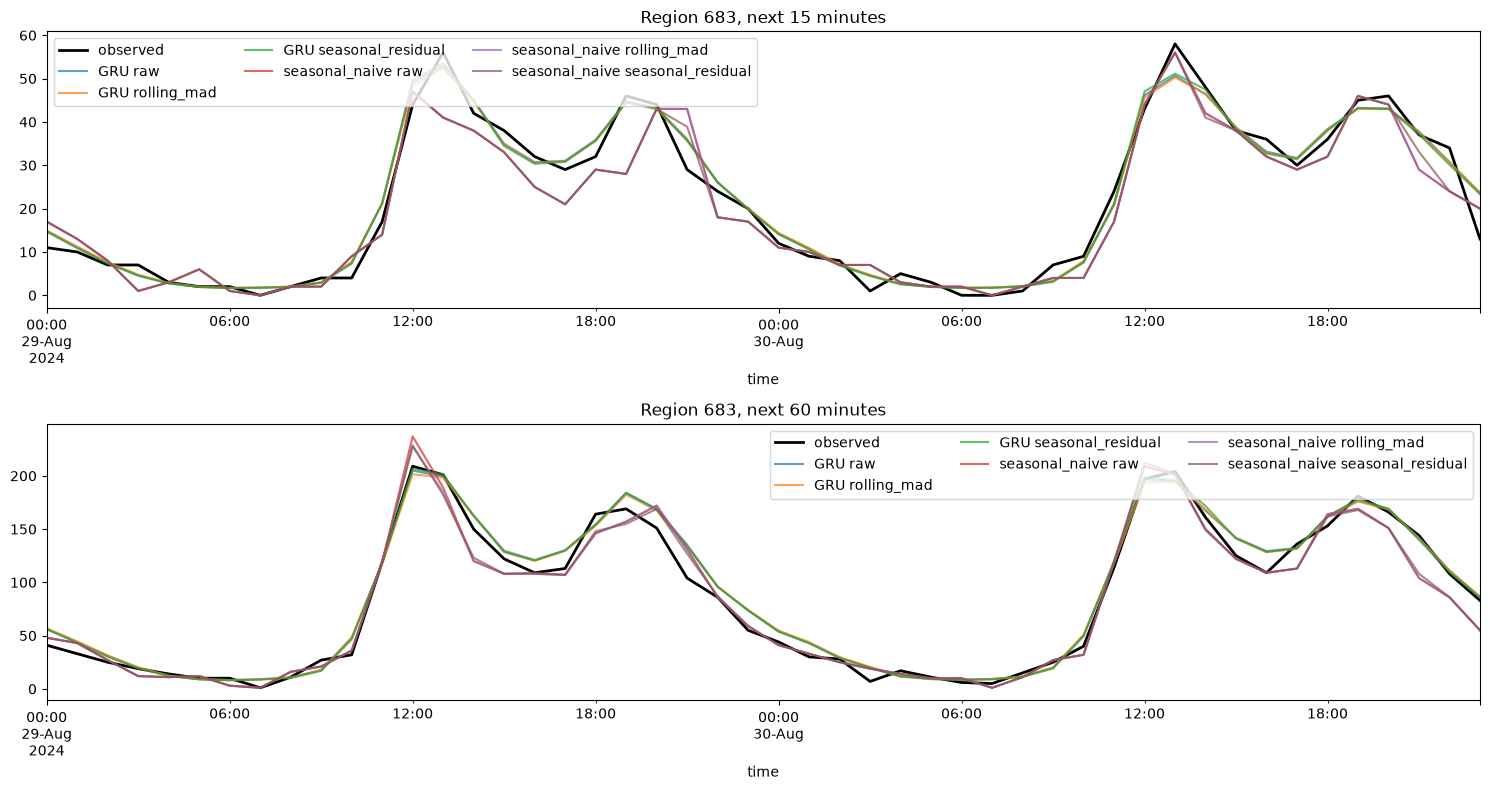

Lowest mean validation MAE for 15 minutes: GRU, rolling_mad, MAE=1.163, RMSE=1.991
Lowest mean validation MAE for 60 minutes: GRU, rolling_mad, MAE=2.807, RMSE=5.104


In [8]:
regional = pd.DataFrame(metric_rows)
predictions = pd.concat(prediction_rows, ignore_index=True)
pooled_rows = []
for keys, group in predictions.groupby(['fold','method','model','horizon']):
    pooled_rows.append(dict(zip(['fold','method','model','horizon'],keys), MAE=mean_absolute_error(group.true,group.predicted), RMSE=np.sqrt(mean_squared_error(group.true,group.predicted))))
pooled = pd.DataFrame(pooled_rows)
summary = pooled.groupby(['method','model','horizon'])[['MAE','RMSE']].agg(['mean','std'])
display(summary)
summary.to_csv(OUT / 'summary.csv')
display(regional.groupby(['method','model','horizon','region'])[['MAE','RMSE']].mean())
means = pooled.groupby(['method','model','horizon'])[['MAE','RMSE']].mean().reset_index()
reference = means[means.method == 'raw'].drop(columns='method')
comparison = means.merge(reference, on=['model','horizon'], suffixes=('', '_raw'))
comparison['MAE_change'] = comparison.MAE - comparison.MAE_raw
comparison['RMSE_change'] = comparison.RMSE - comparison.RMSE_raw
display(comparison)
comparison.to_csv(OUT / 'treatment_comparison.csv', index=False)
fig, axes = plt.subplots(2, 1, figsize=(15, 8))
for ax, horizon in zip(axes, HORIZONS):
    part = predictions[(predictions.fold == 3) & (predictions.region == plot_region) & (predictions.horizon == horizon)]
    truth = part.drop_duplicates('time').set_index('time').true
    truth.iloc[:48].plot(ax=ax, label='observed', color='black', linewidth=2)
    for (model_name, method), group in part.groupby(['model','method']):
        group.set_index('time').predicted.iloc[:48].plot(ax=ax, label=model_name+' '+method, alpha=0.7)
    ax.set_title(f'Region {plot_region}, next {horizon} minutes')
    ax.legend(ncol=3)
plt.tight_layout()
plt.show()
for horizon in HORIZONS:
    candidates = means[means.horizon == horizon]
    winner = candidates.loc[candidates.MAE.idxmin()]
    print(f'Lowest mean validation MAE for {horizon} minutes: {winner["model"]}, {winner["method"]}, MAE={winner.MAE:.3f}, RMSE={winner.RMSE:.3f}')

## Conclusion and saved models

The printed tables determine whether capping improves either model and horizon. Compare MAE and RMSE changes and their variation across folds before drawing a conclusion. Discuss genuine demand spikes, region activity and the zero-bin assumption. No measured conclusion is claimed before executing this notebook.

Each `task3_results/gru_fold<fold>_<method>.pt` contains GRU weights, regional scales, region order and temporal settings. To restore a model, load the checkpoint with `torch.load(path, map_location=DEVICE, weights_only=True)`, instantiate `OrderGRU(len(checkpoint["regions"]))`, load `checkpoint["state_dict"]`, and call `eval()`. Recreate the same causal treatment and calendar features for the last 288 five-minute bins. Multiply the two outputs by the regional scale and `[3, 12]` to obtain 15- and 60-minute totals. Seasonal naive uses the corresponding interval from the preceding day. Detector settings are defined in `clean_history`; seasonal residual thresholds must be recomputed from the same training history.

Metrics and predictions are saved as CSV files; TensorBoard logs are under `task3_results/runs`. The ZIP and trained artifacts stay on the local machine. Preserve them for submission. Further validation could examine holidays, longer histories and alternative handling of genuine peaks.